
### Contexte du projet

L'objectif global du projet UE Data Mining est de retrouver un **narratif / secret caché** dans des jeux de données **factices** (`data/`), en utilisant les notions vues en cours. Ce narratif est fictif et pédagogique.

Cette partie contribue au secret en croisant textes, signaux cardiaques et tables CSV.

### Objectif de cette partie

1. Préparer et analyser un corpus de **130 documents** (publics, mémos, notes cliniques, rapports environnementaux).
2. Contrôler et analyser **44 signaux cardiaques** (2 canaux).
3. Relier les références textuelles aux CSV et les signaux aux notes cliniques.

### Lien avec le cours

| Séance | Notion utilisée ici |
|---|---|
| Bases de la fouille de données | Chargement, qualité, nettoyage, dictionnaire de données |
| Ordonner et regrouper | TF-IDF + K-Means (documents et signaux), choix de K (silhouette) |
| Patterns et anomalies | Documents atypiques, scores d'anomalie, labels `irregular` / `review_required` |
| Graphes et processus | Réseau de cooccurrences (personnes / orgs / lieux) |
| Données spatiales et temporelles | Signaux cardiaques (séries temporelles), monitoring / sites |
| Données textuelles | Nettoyage NLP, fréquences, n-grammes, TF-IDF |

### Structure du notebook

| Partie | Contenu |
|---|---|
| **A** | Préparation de l'environnement et chargement |
| **B** | Volet 1 — Textes  |
| **C** | Volet 2 — Signaux cardiaques  |
| **D** | Synthèse, livrables et limites  |

Chaque section suit : **Objectif → Méthode → Code → Résultat → Interprétation → Limites**.

Fichiers utiles : `README.md`, `requirements.txt`, `data/`, `PROCESSUS_06_textes_et_signaux.md`.


## Usage de l'IA générative (transparence)

J'ai utilisé une IA générative de façon limitée, pas pour réaliser le projet à ma place.

- **À quoi ça m'a servi** : clarifier quelques algorithmes (TF-IDF, K-Means, silhouette, PCA) et m'aider à mieux lire les graphiques affichés.
- **Ce que j'ai fait moi-même** : le choix des analyses, l'exécution du notebook sur les données du dossier `data/`, la lecture des sorties, et la rédaction des interprétations.
- **Ce que je n'ai pas délégué** : je n'ai pas demandé à l'IA de faire tout le projet ni de remplacer mon analyse des résultats.


---
# Partie A — Environnement et données

## A.1 Importation des bibliothèques

**Pourquoi ces bibliothèques ?**

| Bibliothèque | Usage dans ce notebook |
|---|---|
| `pandas` / `numpy` | tables, agrégations, calculs vectoriels |
| `matplotlib` / `seaborn` | visualisations |
| `scikit-learn` | TF-IDF, K-Means, PCA, silhouette, similarité |
| `scipy.signal` | détection de pics (estimation exploratoire du rythme) |
| `networkx` | réseau de cooccurrences d'entités |
| `nltk` / `re` | tokenisation, stopwords, extraction d'identifiants |


In [1]:
import os
import re
import warnings
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler
from scipy.signal import find_peaks

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 13

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 40)

print("Bibliothèques chargées.")


Bibliothèques chargées.


### Interprétation (A.1)

Les bibliothèques se chargent sans erreur. On a tout ce qu'il faut pour les tableaux, les plots, le NLP simple et le clustering.

## A.2 Chemins et dossier de sortie

Le notebook est placé à la racine du dépôt. Les données sont dans `data/`.
Les résultats intermédiaires seront sauvegardés dans `outputs/`.


In [2]:
DATA_PATH = "data"
OUTPUT_PATH = "outputs"
os.makedirs(OUTPUT_PATH, exist_ok=True)

# Vérification rapide de l'arborescence attendue
expected = [
    "public_records/public_and_investigative_documents.csv",
    "public_records/institutional_memos.csv",
    "health/clinical_notes.csv",
    "ecology/environmental_field_reports.csv",
    "health/cardiac_recordings.csv",
    "health/cardiac_signal_samples.csv",
    "data_dictionary.csv",
]
missing = [p for p in expected if not os.path.exists(os.path.join(DATA_PATH, p))]
if missing:
    raise FileNotFoundError(
        "Fichiers manquants (vérifier DATA_PATH / data.zip) :\n- " + "\n- ".join(missing)
    )
print("Arborescence data/ OK.")
print("Sorties ->", os.path.abspath(OUTPUT_PATH))


Arborescence data/ OK.
Sorties -> C:\Users\Nour\Desktop\projects\20262027-UE-DataMining-Project\outputs


### Interprétation (A.2)

Les chemins `data/` et `outputs/` sont en place. L'arborescence attendue est trouvée, on peut charger les fichiers sans surprise.

## A.3 Chargement des fichiers principaux

### Fichiers textes (130 documents)

| Fichier | Lignes attendues | Dossier |
|---|---|---|
| `public_and_investigative_documents.csv` | 40 | `public_records/` |
| `institutional_memos.csv` | 30 | `public_records/` |
| `clinical_notes.csv` | 30 | `health/` |
| `environmental_field_reports.csv` | 30 | `ecology/` |

### Fichiers signaux

| Fichier | Lignes attendues | Rôle |
|---|---|---|
| `cardiac_recordings.csv` | 44 | métadonnées |
| `cardiac_signal_samples.csv` | 96 925 | échantillons des 2 canaux |


In [3]:
public_docs = pd.read_csv(f"{DATA_PATH}/public_records/public_and_investigative_documents.csv")
memos = pd.read_csv(f"{DATA_PATH}/public_records/institutional_memos.csv")
clinical_notes = pd.read_csv(f"{DATA_PATH}/health/clinical_notes.csv")
environmental_reports = pd.read_csv(f"{DATA_PATH}/ecology/environmental_field_reports.csv")

cardiac_recordings = pd.read_csv(f"{DATA_PATH}/health/cardiac_recordings.csv")
cardiac_samples = pd.read_csv(f"{DATA_PATH}/health/cardiac_signal_samples.csv")
data_dictionary = pd.read_csv(f"{DATA_PATH}/data_dictionary.csv")

counts = {
    "Documents publics": len(public_docs),
    "Mémos": len(memos),
    "Notes cliniques": len(clinical_notes),
    "Rapports environnementaux": len(environmental_reports),
    "Enregistrements cardiaques": len(cardiac_recordings),
    "Échantillons cardiaques": len(cardiac_samples),
}
for k, v in counts.items():
    print(f"{k:30s}: {v}")

assert counts["Documents publics"] == 40
assert counts["Mémos"] == 30
assert counts["Notes cliniques"] == 30
assert counts["Rapports environnementaux"] == 30
assert counts["Enregistrements cardiaques"] == 44
assert counts["Échantillons cardiaques"] == 96925
print("\nContrôles de cardinalité : OK")

Documents publics             : 40
Mémos                         : 30
Notes cliniques               : 30
Rapports environnementaux     : 30
Enregistrements cardiaques    : 44
Échantillons cardiaques       : 96925

Contrôles de cardinalité : OK


### Interprétation (A.3)

Chargement OK : 40 docs publics, 30 mémos, 30 notes cliniques, 30 rapports environnementaux, et 44 enregistrements cardiaques (96925 samples). Les contrôles de cardinalité passent, donc on part sur la bonne base.

## A.4 Fichiers de croisement (validation des références)

Ces tables ne sont **pas** analysées pour elles-mêmes : elles servent à **vérifier** les identifiants cités dans les textes et à relier signaux ↔ patients ↔ notes.


In [4]:
shipments = pd.read_csv(f"{DATA_PATH}/logistics/shipments.csv")
purchase_orders = pd.read_csv(f"{DATA_PATH}/logistics/purchase_order_lines.csv")
patients = pd.read_csv(f"{DATA_PATH}/health/patient_administration.csv")
encounters = pd.read_csv(f"{DATA_PATH}/health/clinical_encounters.csv")
sites = pd.read_csv(f"{DATA_PATH}/ecology/monitoring_sites.csv")
device_ops = pd.read_csv(f"{DATA_PATH}/ecology/monitoring_device_operations.csv")
regulatory_cases = pd.read_csv(f"{DATA_PATH}/public_records/regulatory_case_events.csv")
access_cases = pd.read_csv(f"{DATA_PATH}/public_records/site_access_case_events.csv")
entities = pd.read_csv(f"{DATA_PATH}/public_records/registered_entities.csv")

cross_files = {
    "shipments": shipments,
    "purchase_orders": purchase_orders,
    "patients": patients,
    "encounters": encounters,
    "sites": sites,
    "device_ops": device_ops,
    "regulatory_cases": regulatory_cases,
    "access_cases": access_cases,
    "entities": entities,
}
for name, df in cross_files.items():
    print(f"{name:20s}: {len(df):6d} lignes | colonnes = {list(df.columns)[:4]} ...")


shipments           :    452 lignes | colonnes = ['shipment_number', 'shipment_leg', 'dispatch_time', 'arrival_time'] ...
purchase_orders     :    651 lignes | colonnes = ['purchase_order_number', 'purchase_order_line', 'order_date', 'ordering_facility_code'] ...
patients            :    241 lignes | colonnes = ['patient_number', 'family_name', 'given_name', 'date_of_birth'] ...
encounters          :   1069 lignes | colonnes = ['encounter_number', 'patient_number', 'encounter_start', 'encounter_end'] ...
sites               :     64 lignes | colonnes = ['site_code', 'site_name', 'site_category', 'region'] ...
device_ops          :   4994 lignes | colonnes = ['device_operation_id', 'site_code', 'device_reference', 'operation_start'] ...
regulatory_cases    :    233 lignes | colonnes = ['regulatory_event_id', 'case_number', 'case_category', 'event_time'] ...
access_cases        :    413 lignes | colonnes = ['access_event_id', 'access_case_number', 'site_code', 'event_time'] ...
entities 

### Interprétation (A.4)

Ces tables (shipments, PO, patients, etc.) ne sont pas analysées pour elles-mêmes. Elles serviront plus tard à vérifier si les numéros cités dans les textes existent vraiment dans les CSV.

---
# Partie B — Volet 1 : analyse des textes

> **Mission 1** — Découvrir et préparer les textes  
> Examiner les 130 documents, les harmoniser, les nettoyer.

## B.1 Harmonisation des schémas et fusion du corpus

Les quatre fichiers n'ont **pas** exactement les mêmes colonnes :

| Source | Particularités |
|---|---|
| Publics | `named_location`, `public_or_restricted`, `title` |
| Mémos | `subject_line` (pas `title`), `related_*`, `visibility_level` |
| Notes cliniques | `patient_number`, `encounter_number`, `superseded_document_id`, pas d'`author_name` |
| Environnement | `site_code`, `related_device_reference`, `publication_status` |

**Méthode** : ajouter une colonne `source`, aligner `title` pour les mémos, puis `concat` en conservant toutes les colonnes (`sort=False`).


Étape 3 — Fusionner les quatre fichiers textuels
L'objectif est de travailler sur un seul DataFrame contenant les 130 documents.

In [5]:
public_docs = public_docs.copy()
memos = memos.copy()
clinical_notes = clinical_notes.copy()
environmental_reports = environmental_reports.copy()

public_docs["source"] = "public"
memos["source"] = "institutional"
clinical_notes["source"] = "clinical"
environmental_reports["source"] = "environmental"

# Harmoniser le titre des mémos
if "title" not in memos.columns and "subject_line" in memos.columns:
    memos["title"] = memos["subject_line"]

documents = pd.concat(
    [public_docs, memos, clinical_notes, environmental_reports],
    ignore_index=True,
    sort=False,
)

print("Nombre total de documents :", len(documents))
print("Sources :")
print(documents["source"].value_counts())
print("\nAperçu des colonnes communes utiles :")
display(documents[["document_id", "source", "document_type", "title", "text"]].head())


Nombre total de documents : 130
Sources :


source
public           40
institutional    30
clinical         30
environmental    30
Name: count, dtype: int64

Aperçu des colonnes communes utiles :


,document_id,source,document_type,title,text
0,PUB-510045,public,confidential_briefing,Restricted Review of Recurrent Executive Health Interventions,PURPOSE\r\nThis restricted briefing summarizes a small set of senior office-holders and corporate leaders who have r...
1,PUB-510094,public,research_summary,Opposed Ecological Strategies and Disclosure,QUESTION\r\nWhy do two groups using similar ecological language recommend sharply different forms of action?\r\n\r\n...
2,PUB-510043,public,historical_letter,Letter from the Vosmere Commercial Papers,"6 November 1942\r\n\r\nDear M.,\r\n\r\nYour note reached me at the old Wren Street address, though the forwarding cl..."
3,PUB-510033,public,meeting_extract,Extract from the Eastern Orchard Programme Minutes,"EXTRACT FROM MINUTES — 18 MAY 1962\r\n\r\nPresent: Jonah Bell, Julien Marot, Jacob Vale, two representatives of the ..."
4,PUB-510044,public,investigative_note,Jacob Vale Identity-Continuity Lead,"LEAD\r\nJacob Vale may be connected to an unusual clinical subject and to a set of historical aliases, but the chain..."


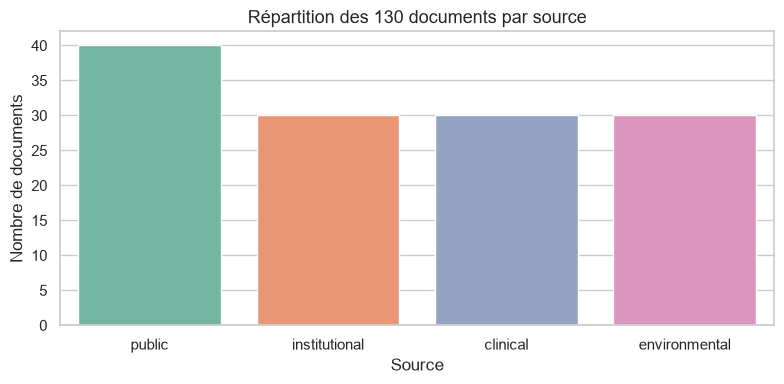

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
order = documents["source"].value_counts().index
sns.countplot(data=documents, x="source", order=order, ax=ax, palette="Set2")
ax.set_title("Répartition des 130 documents par source")
ax.set_xlabel("Source")
ax.set_ylabel("Nombre de documents")
plt.tight_layout()
plt.show()


### Interprétation (B.1)

On a bien les 130 documents attendus : 40 publics, 30 mémos, 30 notes cliniques et 30 rapports environnementaux. Tout est dans un seul tableau, avec la colonne `source` qui garde l'origine de chaque texte. C'est important pour plus tard, surtout pour voir si les thèmes croisent plusieurs types de documents.


## B.2 Qualité des données textuelles

Avant d'appliquer les méthodes NLP, il faut vérifier la qualité des données.

Contrôles : valeurs manquantes, doublons d'`document_id`, distribution des longueurs.


In [7]:
print("Dimensions :", documents.shape)
print("\nValeurs manquantes (colonnes clés) :")
key_cols = [c for c in ["document_id", "document_type", "title", "text", "document_date"] if c in documents.columns]
print(documents[key_cols].isnull().sum())

print("\nDoublons document_id :", documents["document_id"].duplicated().sum())

documents["text_length"] = documents["text"].fillna("").astype(str).str.len()
documents["word_count_raw"] = documents["text"].fillna("").astype(str).str.split().str.len()

print("\nLongueur des textes (caractères) :")
display(documents["text_length"].describe().to_frame("text_length"))

display(
    documents[["document_id", "source", "title", "text_length", "word_count_raw"]]
    .sort_values("text_length", ascending=False)
    .head(10)
)


Dimensions : (130, 29)

Valeurs manquantes (colonnes clés) :
document_id      0
document_type    0
title            0
text             0
document_date    0
dtype: int64

Doublons document_id : 0

Longueur des textes (caractères) :


,text_length
count,130.000000
mean,1352.023077
std,470.254878
min,593.000000
25%,962.250000
50%,1282.000000
75%,1517.250000
max,2301.000000


,document_id,source,title,text_length,word_count_raw
8,PUB-510121,public,Policy Review Memorandum 83,2301,268
107,EFR-510026,environmental,Monthly Monitoring Report 33,2285,288
31,PUB-510070,public,Research Summary 106,2260,281
18,PUB-510068,public,Oversight Committee Minutes 93,2204,260
17,PUB-510024,public,Oversight Committee Minutes 92,2204,260
14,PUB-510049,public,Confidential Review Briefing 89,2175,250
10,PUB-510084,public,Policy Review Memorandum 85,2155,253
85,CLN-510039,clinical,Specialist Consultation 12,2152,269
6,PUB-510063,public,Restricted Classification and External-Transfer Assessment,2147,290
9,PUB-510103,public,Policy Review Memorandum 84,2139,253


Visualiser la longueur des textes :

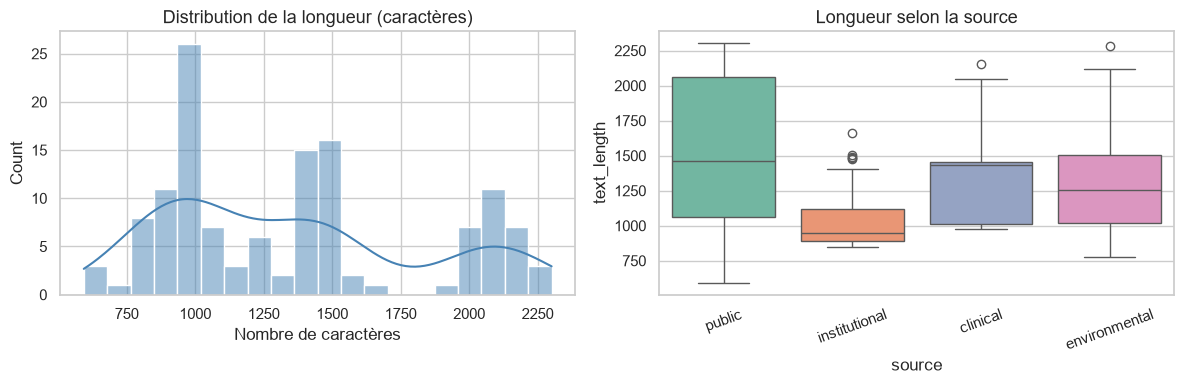

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(documents["text_length"], bins=20, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution de la longueur (caractères)")
axes[0].set_xlabel("Nombre de caractères")

sns.boxplot(data=documents, x="source", y="text_length", ax=axes[1], palette="Set2")
axes[1].set_title("Longueur selon la source")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


Tu peux également identifier les documents les plus longs :

In [9]:
documents[
    ["document_id", "source", "title", "text_length"]
].sort_values(
    by="text_length",
    ascending=False
).head(10)

,document_id,source,title,text_length
8,PUB-510121,public,Policy Review Memorandum 83,2301
107,EFR-510026,environmental,Monthly Monitoring Report 33,2285
31,PUB-510070,public,Research Summary 106,2260
18,PUB-510068,public,Oversight Committee Minutes 93,2204
17,PUB-510024,public,Oversight Committee Minutes 92,2204
14,PUB-510049,public,Confidential Review Briefing 89,2175
10,PUB-510084,public,Policy Review Memorandum 85,2155
85,CLN-510039,clinical,Specialist Consultation 12,2152
6,PUB-510063,public,Restricted Classification and External-Transfer Assessment,2147
9,PUB-510103,public,Policy Review Memorandum 84,2139


### Interprétation (B.2)

Pas de trou sur les colonnes clés, et aucun doublon d'`document_id`. Les textes font en moyenne ~1330 caractères (min 585, max 2252). Les plus longs sont surtout des documents publics (mémorandums, minutes) et un rapport environnemental. Limite : un texte long n'est pas forcément plus intéressant ; il peut juste peser plus dans un TF-IDF si on n'y fait pas attention.


## B.3 Nettoyage et normalisation NLP

**Opérations** : minuscules → suppression ponctuation (sauf chiffres utiles déjà tokenisés) → tokenisation → stopwords anglais + stopwords métier peu informatifs → mots trop courts.
On va préparer les textes pour pouvoir les analyser automatiquement.

Les opérations :
1. Passage en minuscules.
2. Suppression des caractères spéciaux.
3. Suppression des espaces inutiles.
4. Tokenisation.
5. Suppression des mots vides (stopwords).
Les textes du corpus sont en anglais. Il faut donc utiliser des stopwords anglais.

> On conserve toujours la colonne `text` originale : les identifiants (`SHP-...`, `PAT-...`) et les noms propres y restent intacts.


In [10]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

for resource in ["punkt", "punkt_tab", "stopwords"]:
    try:
        nltk.data.find(f"tokenizers/{resource}" if "punkt" in resource else f"corpora/{resource}")
    except LookupError:
        nltk.download(resource, quiet=True)

stop_words = set(stopwords.words("english"))
custom_stopwords = {
    "document", "report", "review", "record", "records", "information",
    "following", "section", "shall", "would", "could", "also", "may",
    "within", "including", "related", "note", "notes",
}
stop_words.update(custom_stopwords)

# fct de nettoyage
def clean_text(text):
    if pd.isna(text):
        return ""
    text = str(text).lower()
    # Suppression des caractères spéciaux
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    # Suppression des espaces multiples
    text = re.sub(r"\s+", " ", text).strip()
    # Tokenisation
    tokens = word_tokenize(text)
    # Suppression des stopwords et mots trop courts
    tokens = [w for w in tokens if w not in stop_words and len(w) > 2]
    return " ".join(tokens)


documents["clean_text"] = documents["text"].apply(clean_text)
documents["token_count"] = documents["clean_text"].str.split().str.len().fillna(0).astype(int)

display(documents[["document_id", "source", "title", "token_count", "clean_text"]].head())
print("Tokens moyens par document :", round(documents["token_count"].mean(), 1))


,document_id,source,title,token_count,clean_text
0,PUB-510045,public,Restricted Review of Recurrent Executive Health Interventions,177,purpose restricted briefing summarizes small set senior office holders corporate leaders received recurrent confiden...
1,PUB-510094,public,Opposed Ecological Strategies and Disclosure,178,question two groups using similar ecological language recommend sharply different forms action method public stateme...
2,PUB-510043,public,Letter from the Vosmere Commercial Papers,119,november 1942 dear reached old wren street address though forwarding clerk placed among natural history circulars pl...
3,PUB-510033,public,Extract from the Eastern Orchard Programme Minutes,133,extract minutes 1962 present jonah bell julien marot jacob vale two representatives agricultural improvement board s...
4,PUB-510044,public,Jacob Vale Identity-Continuity Lead,131,lead jacob vale connected unusual clinical subject set historical aliases chain remains incomplete evidence restrict...


Tokens moyens par document : 117.8


In [11]:
# Sauvegarde du corpus préparé (livrable)
prepared_cols = [
    c for c in [
        "document_id", "source", "document_type", "document_date", "title",
        "text", "clean_text", "text_length", "token_count",
        "author_name", "author_organization", "named_location", "site_code",
        "patient_number", "encounter_number", "superseded_document_id",
        "public_or_restricted", "visibility_level", "confidentiality_class",
        "publication_status",
    ] if c in documents.columns
]
documents[prepared_cols].to_csv(f"{OUTPUT_PATH}/prepared_documents.csv", index=False)
print("Sauvegardé : outputs/prepared_documents.csv")


Sauvegardé : outputs/prepared_documents.csv


### Interprétation (B.3)

Après nettoyage (minuscules, tokens, stopwords anglais), le texte est plus homogène pour TF-IDF / fréquences. On garde aussi le fichier `prepared_documents.csv` : c'est le corpus prêt pour la suite. Limite : on perd un peu de nuance (noms propres, formulations), mais c'est normal pour ce type d'analyse.

## B.4 Fréquences de mots et n-grammes

> **Mission 3 (début)** — repérer les termes et expressions récurrents avant le clustering.


,word,frequency
0,ordinary,239
1,device,176
2,concerns,153
3,observations,129
4,recorded,128
5,evidence,124
6,source,119
7,quality,111
8,interval,104
9,reviewed,101


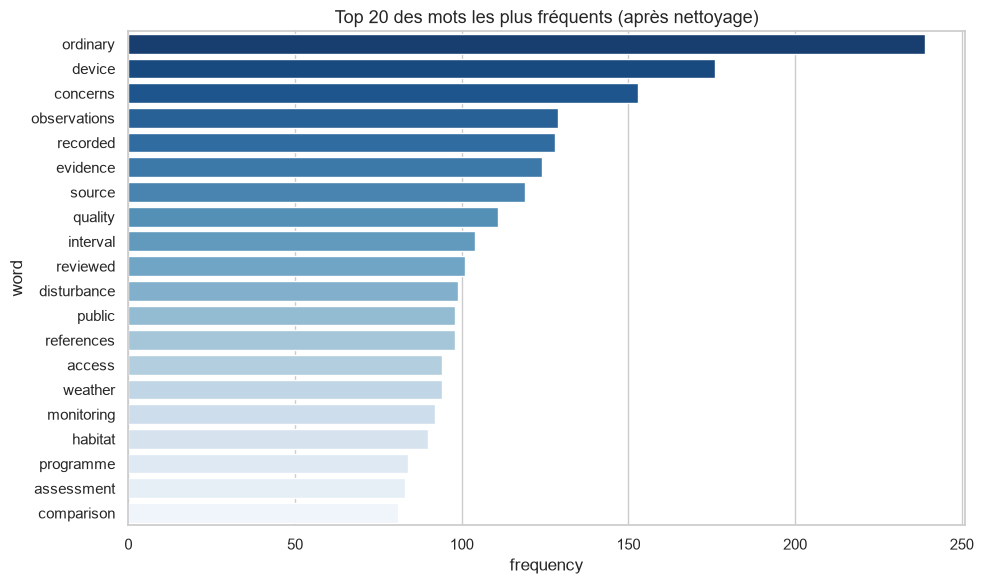

In [12]:
all_words = " ".join(documents["clean_text"].fillna("")).split()
word_counts = Counter(all_words)
freq_df = pd.DataFrame(word_counts.most_common(20), columns=["word", "frequency"])
display(freq_df)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=freq_df, x="frequency", y="word", ax=ax, palette="Blues_r")
ax.set_title("Top 20 des mots les plus fréquents (après nettoyage)")
plt.tight_layout()
plt.show()


Analyse des expressions (n-grammes)
Un unigramme est un mot seul, un bigramme est une expression de deux mots et un trigramme contient trois mots.

Exemple :
- shipment
- biological sample
- restricted access procedure

In [13]:
vectorizer_ngrams = TfidfVectorizer(
    ngram_range=(2, 3),
    stop_words="english",
    max_features=40,
    min_df=2,
)
X_ngrams = vectorizer_ngrams.fit_transform(documents["clean_text"].fillna(""))
ngram_df = (
    pd.DataFrame({
        "expression": vectorizer_ngrams.get_feature_names_out(),
        "score_tfidf_sum": np.asarray(X_ngrams.sum(axis=0)).flatten(),
    })
    .sort_values("score_tfidf_sum", ascending=False)
)
display(ngram_df.head(20))


,expression,score_tfidf_sum
35,source local,22.475511
5,device quality,12.128413
3,clinical team,9.297431
0,available clinical,9.297431
21,limited observations,9.297431
22,limited observations available,9.297431
23,observations available,9.297431
1,available clinical team,9.297431
24,observations available clinical,9.297431
9,effort weather,6.529384


### Interprétation (B.4)

Les mots les plus fréquents (`ordinary`, `device`, `concerns`, `observations`, `evidence`…) montrent un corpus assez « technique / surveillance ». Les n-grammes aident plus : on voit des expressions comme `device quality`, `clinical team`, `effort weather`, `reporting interval`. Ça oriente déjà vers la qualité des appareils, le suivi clinique et le monitoring environnemental.


## B.5 Regroupement thématique (TF-IDF + K-Means)(clustering)
L'objectif est de découvrir si les 130 documents peuvent être regroupés automatiquement selon leur contenu.

> **Mission 3** — Regrouper les documents par sujet et identifier les mots caractéristiques.

**Méthode**
1. Représentation TF-IDF (`max_features=1000`, unigrammes + bigrammes).
2. Choix de `K` via le **score de silhouette** (K = 2…8).
3. Interprétation des centres (top termes) + lecture d'exemples.
4. Projection PCA 2D pour visualisation (exploratoire).

TF-IDF donne plus d'importance aux mots caractéristiques d'un document et moins d'importance aux mots présents partout.


Dimensions matrice TF-IDF : (130, 1000)


,k,silhouette
0,2,0.145334
1,3,0.211481
2,4,0.261581
3,5,0.308597
4,6,0.342415
5,7,0.352734
6,8,0.343541


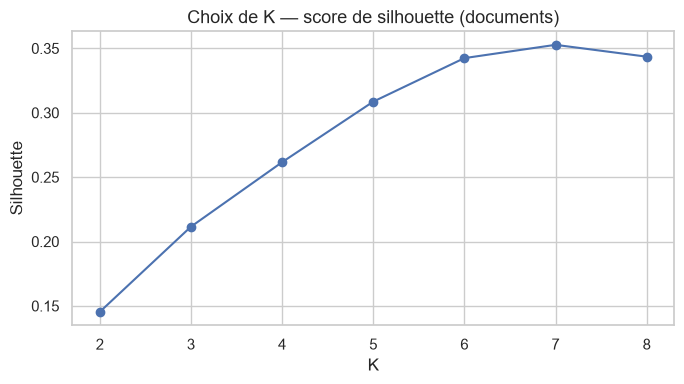

In [14]:
# Transformation TF-IDF
tfidf = TfidfVectorizer(
    max_features=1000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.90,
    stop_words="english",
)
X = tfidf.fit_transform(documents["clean_text"].fillna(""))
print("Dimensions matrice TF-IDF :", X.shape)

# Choisir le nombre de clusters
silhouette_rows = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X)
    silhouette_rows.append({"k": k, "silhouette": silhouette_score(X, labels)})

scores_df = pd.DataFrame(silhouette_rows)
display(scores_df)
# Visualisation
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(scores_df["k"], scores_df["silhouette"], marker="o")
ax.set_title("Choix de K — score de silhouette (documents)")
ax.set_xlabel("K")
ax.set_ylabel("Silhouette")
plt.tight_layout()
plt.show()


Le Silhouette Score mesure deux éléments :

- Cohésion : les documents d'un même cluster doivent être proches les uns des autres.

- Séparation : les différents clusters doivent être éloignés les uns des autres.

Le score est compris entre -1 et 1 :

| **Score** | **Interprétation** |
|:---:|---|
| Proche de 1 | Clusters bien séparés |
| Proche de 0 | Clusters qui se chevauchent |
| Négatif | Documents potentiellement mal affectés |

In [15]:
# Appliquer K-Means
best_k = int(scores_df.loc[scores_df["silhouette"].idxmax(), "k"])
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=20)
documents["cluster"] = kmeans.fit_predict(X)
print("K retenu :", best_k)

# Identifier les mots caractéristiques de chaque groupe
terms = tfidf.get_feature_names_out()
cluster_profiles = []
for cluster_id in sorted(documents["cluster"].unique()):
    center = kmeans.cluster_centers_[cluster_id]
    top_idx = center.argsort()[-12:][::-1]
    top_words = [terms[i] for i in top_idx]
    cluster_profiles.append({
        "cluster": cluster_id,
        "n_docs": int((documents["cluster"] == cluster_id).sum()),
        "top_terms": ", ".join(top_words),
    })
    print(f"\n=== CLUSTER {cluster_id} ({(documents['cluster'] == cluster_id).sum()} docs) ===")
    print(", ".join(top_words))

cluster_profiles_df = pd.DataFrame(cluster_profiles)
display(cluster_profiles_df)

# Composition par source
display(pd.crosstab(documents["cluster"], documents["source"]))


K retenu : 7

=== CLUSTER 0 (16 docs) ===
public, historical, biological, continuity, restricted, vale, use, classification, identity, ocular, ordinary, jacob

=== CLUSTER 1 (27 docs) ===
supplier, owner, procurement, shipment, ordinary, posting, inventory, timing, substitution, adjustment, codes, facility codes

=== CLUSTER 2 (26 docs) ===
patient, assessment, follow, clinical, measurements, technical, risk, prior, encounter, history, observations available, limited observations

=== CLUSTER 3 (29 docs) ===
device, disturbance, weather, interval, habitat, monitoring, bat, survey, comparison, effort, effort weather, limitations

=== CLUSTER 4 (11 docs) ===
public, issuing, body, issuing body, matter, mandate, confidentiality, documented mandate, body documented, matter concerns, options, official

=== CLUSTER 5 (14 docs) ===
justice, accountability, climate, verification, publicly, independent, verification transparent, author calls, claims separated, independent verification, using at

,cluster,n_docs,top_terms
0,0,16,"public, historical, biological, continuity, restricted, vale, use, classification, identity, ocular, ordinary, jacob"
1,1,27,"supplier, owner, procurement, shipment, ordinary, posting, inventory, timing, substitution, adjustment, codes, facil..."
2,2,26,"patient, assessment, follow, clinical, measurements, technical, risk, prior, encounter, history, observations availa..."
3,3,29,"device, disturbance, weather, interval, habitat, monitoring, bat, survey, comparison, effort, effort weather, limita..."
4,4,11,"public, issuing, body, issuing body, matter, mandate, confidentiality, documented mandate, body documented, matter c..."
5,5,14,"justice, accountability, climate, verification, publicly, independent, verification transparent, author calls, claim..."
6,6,7,"provenance, archival, item, catalog, presented provenance, transcription, relates, provenance transcription, item re..."


source,clinical,environmental,institutional,public
cluster,,,,
0,4,1,3,8
1,0,0,27,0
2,26,0,0,0
3,0,29,0,0
4,0,0,0,11
5,0,0,0,14
6,0,0,0,7


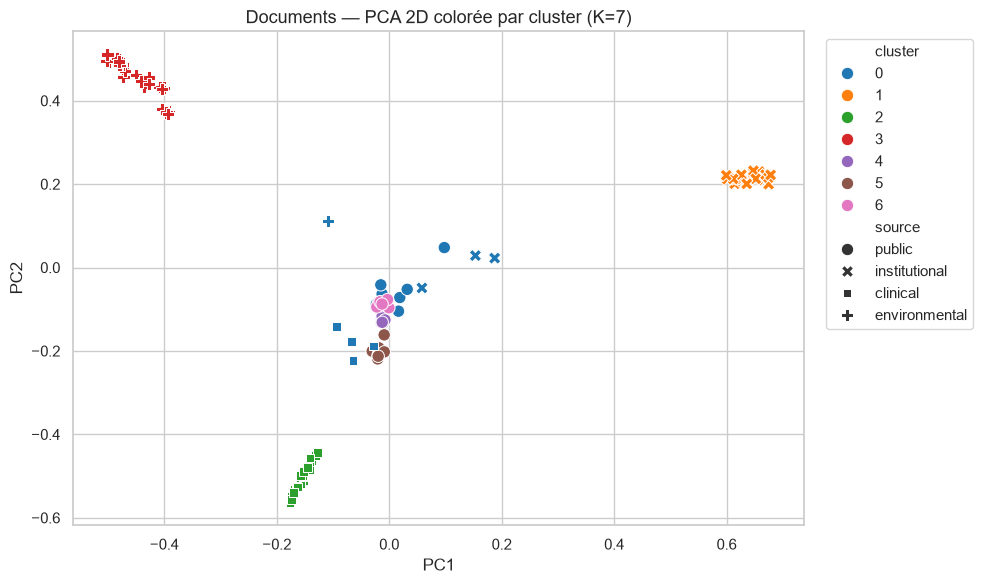

Variance expliquée PCA : 28.8%


In [16]:
# Visualiser les clusters avec PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X.toarray())
documents["PC1"] = X_pca[:, 0]
documents["PC2"] = X_pca[:, 1]

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=documents, x="PC1", y="PC2",
    hue="cluster", style="source",
    palette="tab10", s=80, ax=ax,
)
ax.set_title(f"Documents — PCA 2D colorée par cluster (K={best_k})")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
print(f"Variance expliquée PCA : {pca.explained_variance_ratio_.sum():.1%}")


In [17]:
# Exemples de titres par cluster
for cluster_id in sorted(documents["cluster"].unique()):
    print(f"\n---------- CLUSTER {cluster_id} ----------")
    subset = documents[documents["cluster"] == cluster_id][
        ["document_id", "source", "title"]
    ].head(8)
    display(subset)



---------- CLUSTER 0 ----------


,document_id,source,title
0,PUB-510045,public,Restricted Review of Recurrent Executive Health Interventions
1,PUB-510094,public,Opposed Ecological Strategies and Disclosure
2,PUB-510043,public,Letter from the Vosmere Commercial Papers
3,PUB-510033,public,Extract from the Eastern Orchard Programme Minutes
4,PUB-510044,public,Jacob Vale Identity-Continuity Lead
5,PUB-510079,public,Message Concerning Collected Eonycteris
6,PUB-510063,public,Restricted Classification and External-Transfer Assessment
7,PUB-510076,public,Catalog Note on Recurrent Historical Identifiers



---------- CLUSTER 1 ----------


,document_id,source,title
43,MEM-510128,institutional,Internal Operations Memorandum 56
44,MEM-510069,institutional,Internal Operations Memorandum 57
45,MEM-510030,institutional,Internal Operations Memorandum 58
46,MEM-510080,institutional,Internal Operations Memorandum 59
47,MEM-510059,institutional,Internal Operations Memorandum 60
48,MEM-510074,institutional,Procurement Justification 61
49,MEM-510018,institutional,Procurement Justification 62
50,MEM-510021,institutional,Procurement Justification 63



---------- CLUSTER 2 ----------


,document_id,source,title
74,CLN-510107,clinical,Clinical Summary 01
75,CLN-510113,clinical,Clinical Summary 02
76,CLN-510009,clinical,Clinical Summary 03
77,CLN-510010,clinical,Clinical Summary 04
78,CLN-510087,clinical,Clinical Summary 05
79,CLN-510081,clinical,Clinical Summary 06
80,CLN-510126,clinical,Thoracic Imaging Report 07
81,CLN-510129,clinical,Thoracic Imaging Report 08


... (4 outputs left out)


---------- CLUSTER 5 ----------


,document_id,source,title
19,PUB-510111,public,Campaign Statement 94
20,PUB-510073,public,Campaign Statement 95
21,PUB-510051,public,Campaign Statement 96
22,PUB-510071,public,Open Letter on Public Records 97
23,PUB-510052,public,Open Letter on Public Records 98
24,PUB-510056,public,Open Letter on Public Records 99
25,PUB-510078,public,Witness Testimony 100
26,PUB-510066,public,Witness Testimony 101



---------- CLUSTER 6 ----------


,document_id,source,title
33,PUB-510041,public,Corporate Archive Catalog Note 108
34,PUB-510083,public,Historical Correspondence 109
35,PUB-510004,public,Registry Extract 110
36,PUB-510040,public,Registry Extract 111
37,PUB-510001,public,Historical Meeting Extract 112
38,PUB-510127,public,Private Historical Note 113
39,PUB-510046,public,Private Historical Note 114


### Interprétation (B.5)

Le meilleur silhouette est pour **K = 7** (≈ 0.35). Ce n'est pas un score très haut, mais c'est le meilleur parmi K = 2…8, et les thèmes restent lisibles.

Lecture rapide des groupes :
- **Cluster 0** : documents plutôt historiques / identité (Jacob Vale, continuité, classification) — mélange public + quelques notes/mémos.
- **Cluster 1** : logistique / achats (`supplier`, `shipment`, `procurement`) — **uniquement** des mémos institutionnels.
- **Cluster 2** : notes cliniques (`patient`, `assessment`, `encounter`) — **uniquement** clinical.
- **Cluster 3** : monitoring terrain (`device`, `weather`, `habitat`, `bat`) — **uniquement** environmental.
- **Clusters 4–6** : documents publics (statements officiels, campagnes / justice, archives / provenance).

Donc une partie des clusters suit presque les sources (1, 2, 3), tandis que le cluster 0 mélange un peu les origines : c'est intéressant pour le narratif transversal.

Limite : la PCA n'explique que ~29 % de la variance en 2D, donc le nuage est juste une vue d'ensemble. K-Means reste une aide à la lecture, pas une preuve de thèmes « vrais » sans ouvrir les textes.


## B.6 Extraction et validation des références

> **Mission 2** — Extraire automatiquement les numéros cités.  
> **Mission 8** — Pour chaque numéro, retrouver la ligne CSV et résumer le lien.

On travaille sur le **texte original**. On combine :
1. **regex** sur `text` ;
2. **colonnes structurées** déjà présentes (`related_shipment_number`, `patient_number`, etc.)


On travaille sur le texte original, et non sur clean_text, afin de conserver les identifiants exactement.

In [18]:
shipments = pd.read_csv(
    f"{DATA_PATH}/logistics/shipments.csv"
)

purchase_orders = pd.read_csv(
    f"{DATA_PATH}/logistics/purchase_order_lines.csv"
)

patients = pd.read_csv(
    f"{DATA_PATH}/health/patient_administration.csv"
)

encounters = pd.read_csv(
    f"{DATA_PATH}/health/clinical_encounters.csv"
)

sites = pd.read_csv(
    f"{DATA_PATH}/ecology/monitoring_sites.csv"
)

regulatory_cases = pd.read_csv(
    f"{DATA_PATH}/public_records/regulatory_case_events.csv"
)

access_cases = pd.read_csv(
    f"{DATA_PATH}/public_records/site_access_case_events.csv"
)

entities = pd.read_csv(
    f"{DATA_PATH}/public_records/registered_entities.csv"
)

In [19]:
# Extraire les identifiants avec Regex
patterns = {
    "shipment": r"\bSHP-\d{4}-\d+\b",
    "purchase_order": r"\bPO-\d{4}-\d+\b",
    "patient": r"\bPAT-\d+\b",
    "encounter": r"\bENC-\d+\b",
    "site": r"\b[A-Z]{3}-[A-Z]{3}\b",
    "regulatory_case": r"\bREG-\d{4}-\d+\b",
    "registration": r"\bREG-[A-Z]{3}-\d+\b",
    "document_ref": r"\b(?:PUB|MEM|CLN|EFR)-\d+\b",
    "device": r"\bDEV-\d+\b",
}


def extract_references(text):
    if pd.isna(text):
        return {k: [] for k in patterns}
    text = str(text)
    return {cat: sorted(set(re.findall(pat, text))) for cat, pat in patterns.items()}


documents["references"] = documents["text"].apply(extract_references)

# Enrichissement via colonnes structurées
structured_map = [
    ("related_shipment_number", "shipment"),
    ("related_purchase_order", "purchase_order"),
    ("related_case_number", "regulatory_case"),
    ("patient_number", "patient"),
    ("encounter_number", "encounter"),
    ("site_code", "site"),
    ("related_device_reference", "device"),
]

for _, row in documents.iterrows():
    refs = dict(row["references"])
    for col, cat in structured_map:
        if col in documents.columns and pd.notna(row.get(col)):
            val = str(row[col]).strip()
            if val and val not in refs.get(cat, []):
                refs[cat] = sorted(set(refs.get(cat, []) + [val]))
    documents.at[row.name, "references"] = refs

display(documents[["document_id", "source", "references"]].head(8))


,document_id,source,references
0,PUB-510045,public,"{'shipment': [], 'purchase_order': [], 'patient': [], 'encounter': [], 'site': [], 'regulatory_case': [], 'registrat..."
1,PUB-510094,public,"{'shipment': [], 'purchase_order': [], 'patient': [], 'encounter': [], 'site': [], 'regulatory_case': [], 'registrat..."
2,PUB-510043,public,"{'shipment': [], 'purchase_order': [], 'patient': [], 'encounter': [], 'site': [], 'regulatory_case': [], 'registrat..."
3,PUB-510033,public,"{'shipment': [], 'purchase_order': [], 'patient': [], 'encounter': [], 'site': [], 'regulatory_case': [], 'registrat..."
4,PUB-510044,public,"{'shipment': [], 'purchase_order': [], 'patient': [], 'encounter': [], 'site': [], 'regulatory_case': [], 'registrat..."
5,PUB-510079,public,"{'shipment': [], 'purchase_order': [], 'patient': [], 'encounter': [], 'site': [], 'regulatory_case': [], 'registrat..."
6,PUB-510063,public,"{'shipment': [], 'purchase_order': [], 'patient': [], 'encounter': [], 'site': [], 'regulatory_case': [], 'registrat..."
7,PUB-510076,public,"{'shipment': [], 'purchase_order': [], 'patient': [], 'encounter': [], 'site': [], 'regulatory_case': [], 'registrat..."


In [20]:
# Vérifier les identifiants dans les CSV
# On crée un dictionnaire reliant chaque type de référence à sa colonne de destination.
reference_tables = {
    "shipment": (shipments, "shipment_number"),
    "purchase_order": (purchase_orders, "purchase_order_number"),
    "patient": (patients, "patient_number"),
    "encounter": (encounters, "encounter_number"),
    "site": (sites, "site_code"),
    "regulatory_case": (regulatory_cases, "case_number"),
    "registration": (entities, "registration_number"),
    "device": (device_ops, "device_reference"),
    "document_ref": (documents, "document_id"),
}

# Jeux de valeurs pour validation rapide
lookup_sets = {
    cat: set(df[col].dropna().astype(str)) for cat, (df, col) in reference_tables.items()
}

# Fonction de validation :
def validate_reference(category, reference):
    if category not in lookup_sets:
        return None
    return reference in lookup_sets[category]

# Créer un tableau détaillé :
reference_rows = []
for _, row in documents.iterrows():
    for category, refs in row["references"].items():
        for reference in refs:
            reference_rows.append({
                "document_id": row["document_id"],
                "source": row["source"],
                "title": row.get("title"),
                "reference_type": category,
                "reference": reference,
                "exists_in_csv": validate_reference(category, reference),
            })

references_df = pd.DataFrame(reference_rows)
print("Références extraites :", len(references_df))
display(references_df.head(20))
# Statistiques :
if not references_df.empty:
    summary_refs = (
        references_df.groupby(["reference_type", "exists_in_csv"])
        .size()
        .reset_index(name="count")
        .sort_values(["reference_type", "exists_in_csv"])
    )
    display(summary_refs)

    validated = references_df["exists_in_csv"].dropna()
    print(
        f"Taux de validation : {validated.mean()*100:.1f}% "
        f"({int(validated.sum())}/{len(validated)})"
    )


Références extraites : 143


,document_id,source,title,reference_type,reference,exists_in_csv
0,MEM-510100,institutional,Secure Delivery Record-Handling Instruction,shipment,SHP-2022-00011,True
1,MEM-510101,institutional,Restricted CHAMELEO Governance Review,shipment,SHP-2023-00035,True
2,MEM-510128,institutional,Internal Operations Memorandum 56,shipment,SHP-2020-00019,True
3,MEM-510030,institutional,Internal Operations Memorandum 58,regulatory_case,ACC-2019-0005,False
4,MEM-510080,institutional,Internal Operations Memorandum 59,regulatory_case,REG-2024-0036,True
5,MEM-510059,institutional,Internal Operations Memorandum 60,purchase_order,PO-2022-00044,True
6,MEM-510074,institutional,Procurement Justification 61,shipment,SHP-2022-00025,True
7,MEM-510021,institutional,Procurement Justification 63,regulatory_case,ACC-2018-0024,False
8,MEM-510061,institutional,Procurement Justification 64,regulatory_case,REG-2022-0022,True
9,MEM-510050,institutional,Procurement Justification 65,purchase_order,PO-2023-00038,True


,reference_type,exists_in_csv,count
0,device,True,30
1,encounter,True,30
2,patient,True,30
3,purchase_order,True,5
4,regulatory_case,False,5
5,regulatory_case,True,5
6,shipment,True,8
7,site,True,30


Taux de validation : 96.5% (138/143)


### Interprétation (B.6)

143 références extraites des textes, dont **138 validées** dans les CSV (96,5 %). Patients, encounters, sites et devices matchent bien. Les échecs (5) concernent surtout des `regulatory_case` de type `ACC-...` : absents de la table cible, ou peut-être liés à un autre système / format.

Point important : un ID non trouvé n'est pas forcément faux. Et côté réglementaire, il ne faut pas confondre un `case_number` (ex. REG-2018-0001) avec un numéro d'enregistrement d'organisation (ex. REG-VLN-01001).

## B.7 Personnes, organisations, lieux et cooccurrences

> **Mission 4** — Dresser la liste des noms cités et voir lesquels coapparaissent.

On va commencer par exploiter les colonnes structurées qui fournissent déjà des informations fiables.


In [21]:
# Construire un tableau des entités
entity_records = []
structured_entity_fields = [
    ("author_name", "person_or_author"),
    ("author_organization", "organization"),
    ("named_location", "location"),
    ("site_code", "site"),
]

for _, row in documents.iterrows():
    for field, etype in structured_entity_fields:
        if field in documents.columns and pd.notna(row.get(field)):
            entity_records.append({
                "document_id": row["document_id"],
                "source": row["source"],
                "entity": str(row[field]).strip(),
                "entity_type": etype,
                "origin": "structured_column",
            })

entities_extracted = pd.DataFrame(entity_records)
print("Entités structurées :", len(entities_extracted))
display(entities_extracted.head(20))
display(
    entities_extracted["entity"].value_counts().head(15).rename_axis("entity").reset_index(name="n_docs")
)


Entités structurées :

 268


,document_id,source,entity,entity_type,origin
0,PUB-510045,public,Dr. Lysa Quen,person_or_author,structured_column
1,PUB-510045,public,Orison Medical Audit Board,organization,structured_column
2,PUB-510045,public,Valenne Central District,location,structured_column
3,PUB-510094,public,Selene Aras,person_or_author,structured_column
4,PUB-510094,public,Threshold Earth Observatory,organization,structured_column
5,PUB-510094,public,Threshold Earth Avelora Laboratory,location,structured_column
6,PUB-510043,public,Emil Warden,person_or_author,structured_column
7,PUB-510043,public,Warden Medical Ventures,organization,structured_column
8,PUB-510043,public,Valenne Republic,location,structured_column
9,PUB-510033,public,Jonah Bell,person_or_author,structured_column


,entity,n_docs
0,Valenne Central District,14
1,Threshold Earth Observatory,9
2,Lantern Investigative Bureau,9
3,Horizon Field Research Cooperative,8
4,Meridian BioLogistics,7
5,Pollinator Justice Network,6
6,Belen Agro-Industries,5
7,Avelora Agricultural Resilience Agency,5
8,Threshold Earth Avelora Laboratory,4
9,Avelora Federation,4


Extraire les noms présents dans les textes
Pour compléter les métadonnées, on peut utiliser une expression régulière pour repérer des groupes de mots commençant par des majuscules.

In [22]:
def extract_named_entities_heuristic(text):
    """Heuristique : suites de mots capitalisés (PAS une NER entraînée)."""
    if pd.isna(text):
        return []
    pattern = r"\b[A-Z][a-z]+(?:\s+[A-Z][a-z]+){1,3}\b"
    blacklist = {
        "The", "This", "These", "There", "Then", "When", "Where",
        "Section", "Appendix", "Figure", "Table", "Page",
    }
    found = []
    for m in re.findall(pattern, str(text)):
        if m.split()[0] not in blacklist:
            found.append(m)
    return sorted(set(found))


documents["possible_entities"] = documents["text"].apply(extract_named_entities_heuristic)
display(documents[["document_id", "possible_entities"]].head())
print(
    "Exemples d'entités candidates (heuristique) :",
    Counter([e for lst in documents["possible_entities"] for e in lst]).most_common(15),
)


,document_id,possible_entities
0,PUB-510045,[]
1,PUB-510094,[Jacob Vale]
2,PUB-510043,"[Adrian Vosmere, Elias Voss, Wren Street]"
3,PUB-510033,"[Agricultural Improvement Board, Jacob Vale, Jonah Bell, Julien Marot]"
4,PUB-510044,"[Jacob Vale, Jonah Bell, Julien Marot]"


Exemples d'entités candidates (heuristique) : [('Jacob Vale', 4), ('Jonah Bell', 3), ('Julien Marot', 3), ('Adrian Vosmere', 2), ('Elias Voss', 2), ('Wren Street', 2), ('Agricultural Improvement Board', 1), ('Dear Colleague', 1)]


Construire le réseau de cooccurrences
L'objectif est d'identifier quelles personnes et organisations apparaissent ensemble dans les mêmes documents.

Graphe : 136 nœuds, 188 arêtes


,entity,centrality
99,Valenne Central District,0.096296
25,Horizon Field Research Cooperative,0.088889
8,Threshold Earth Observatory,0.074074
29,Avelora Agricultural Resilience Agency,0.074074
0,Belen Agro-Industries,0.066667
11,Pollinator Justice Network,0.066667
102,Avelora Federation,0.051852
10,KNT-DMJ,0.044444
120,Eastern Avelora Agricultural Cluster,0.044444
20,Lantern Investigative Bureau,0.044444


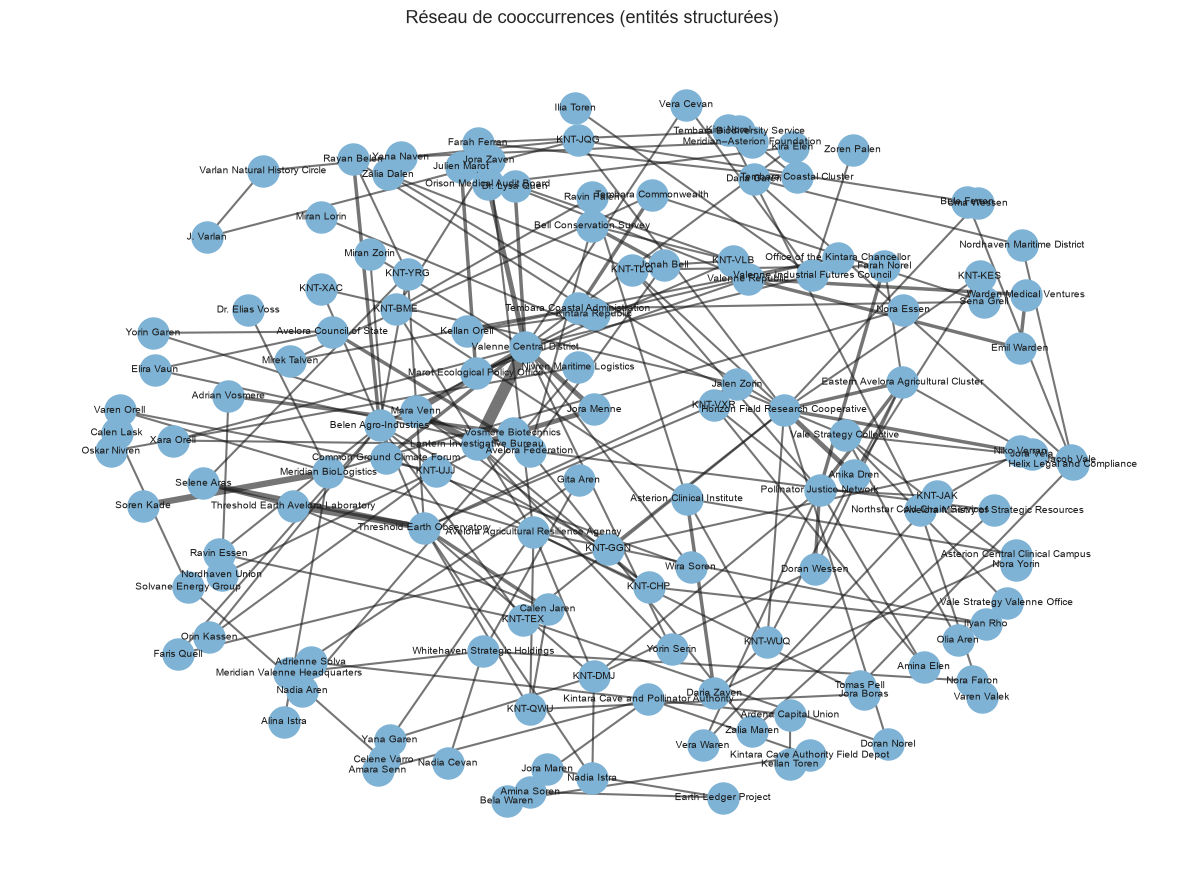

Sauvegardés : extracted_entities.csv | entity_centrality.csv


In [23]:
# Réseau de cooccurrences basé sur les entités STRUCTURÉES (plus fiables)
G = nx.Graph()
for doc_id, group in entities_extracted.groupby("document_id"):
    names = sorted(set(group["entity"]))
    for name in names:
        G.add_node(name)
    for a, b in combinations(names, 2):
        if G.has_edge(a, b):
            G[a][b]["weight"] += 1
        else:
            G.add_edge(a, b, weight=1)

print(f"Graphe : {G.number_of_nodes()} nœuds, {G.number_of_edges()} arêtes")

centrality_df = (
    pd.DataFrame(nx.degree_centrality(G).items(), columns=["entity", "centrality"])
    .sort_values("centrality", ascending=False)
)
display(centrality_df.head(15))

plt.figure(figsize=(12, 9))
if G.number_of_nodes() > 0:
    pos = nx.spring_layout(G, seed=42, k=0.7)
    weights = [G[u][v].get("weight", 1) for u, v in G.edges()]
    nx.draw_networkx_nodes(G, pos, node_size=500, node_color="#7fb3d5")
    nx.draw_networkx_edges(G, pos, width=[0.5 + w for w in weights], alpha=0.6)
    nx.draw_networkx_labels(G, pos, font_size=7)
plt.title("Réseau de cooccurrences (entités structurées)")
plt.axis("off")
plt.tight_layout()
plt.show()

entities_extracted.to_csv(f"{OUTPUT_PATH}/extracted_entities.csv", index=False)
centrality_df.to_csv(f"{OUTPUT_PATH}/entity_centrality.csv", index=False)
print("Sauvegardés : extracted_entities.csv | entity_centrality.csv")


### Interprétation (B.7)

On extrait 268 entités structurées (auteurs, orgs, lieux). Les plus citées : Valenne Central District, Threshold Earth Observatory, Lantern Investigative Bureau, Horizon Field Research Cooperative. Sur le graphe (136 nœuds, 188 liens), Valenne et Horizon ressortent comme les plus centrales.

En gros, ces noms reviennent dans plusieurs documents : ce sont de bons candidats pour relier les volets du récit. Attention : une cooccurrence veut juste dire « cités dans le même doc », pas forcément qu'ils collaborent. Et l'extraction par majuscules reste approximative.


## B.8 Documents remplacés, restreints ou atypiques

> **Mission 5** — Identifier les documents remplacés, restreints ou différents.


In [24]:
# 1) Documents remplacés (notes cliniques)
if "superseded_document_id" in clinical_notes.columns:
    superseded = clinical_notes[clinical_notes["superseded_document_id"].notna()][
        ["document_id", "superseded_document_id", "document_date", "title", "patient_number", "encounter_number"]
    ]
    print("Notes cliniques remplacées / liées à un document antérieur :", len(superseded))
    display(superseded)
else:
    print("Colonne superseded_document_id absente.")

# 2) Niveaux de restriction / visibilité
for column in ["public_or_restricted", "visibility_level", "confidentiality_class", "publication_status"]:
    if column in documents.columns:
        print(f"\n--- {column} ---")
        print(documents[column].value_counts(dropna=False))


Notes cliniques remplacées / liées à un document antérieur : 0


,document_id,superseded_document_id,document_date,title,patient_number,encounter_number



--- public_or_restricted ---
public_or_restricted
NaN           90
public        27
restricted    13
Name: count, dtype: int64

--- visibility_level ---
visibility_level
NaN             100
restricted       11
confidential     10
internal          9
Name: count, dtype: int64

--- confidentiality_class ---
confidentiality_class
NaN             100
standard         12
confidential     11
restricted        7
Name: count, dtype: int64

--- publication_status ---
publication_status
NaN           100
restricted     12
public         10
internal        8
Name: count, dtype: int64


In [25]:
# Documents atypiques par similarité cosinus moyenne (TF-IDF)
similarities = cosine_similarity(X)
mean_similarity = []
for i in range(X.shape[0]):
    scores = np.delete(similarities[i], i)
    mean_similarity.append(float(scores.mean()) if len(scores) else np.nan)

documents["mean_similarity"] = mean_similarity
documents["anomaly_score"] = 1 - documents["mean_similarity"]

atypical_docs = (
    documents[["document_id", "source", "title", "cluster", "mean_similarity", "anomaly_score"]]
    .sort_values("anomaly_score", ascending=False)
)
display(atypical_docs.head(10))

atypical_docs.head(20).to_csv(f"{OUTPUT_PATH}/atypical_documents.csv", index=False)
print("Sauvegardé : atypical_documents.csv")


,document_id,source,title,cluster,mean_similarity,anomaly_score
2,PUB-510043,public,Letter from the Vosmere Commercial Papers,0,0.049583,0.950417
39,PUB-510046,public,Private Historical Note 114,6,0.051580,0.948420
3,PUB-510033,public,Extract from the Eastern Orchard Programme Minutes,0,0.053757,0.946243
38,PUB-510127,public,Private Historical Note 113,6,0.055943,0.944057
42,MEM-510101,institutional,Restricted CHAMELEO Governance Review,0,0.055982,0.944018
37,PUB-510001,public,Historical Meeting Extract 112,6,0.056953,0.943047
35,PUB-510004,public,Registry Extract 110,6,0.058188,0.941812
36,PUB-510040,public,Registry Extract 111,6,0.060092,0.939908
41,MEM-510100,institutional,Secure Delivery Record-Handling Instruction,0,0.060565,0.939435
33,PUB-510041,public,Corporate Archive Catalog Note 108,6,0.061011,0.938989


Sauvegardé : atypical_documents.csv


### Interprétation (B.8)

Aucune note clinique n'est marquée comme remplacée (`superseded`). En revanche, on trouve des documents `restricted` / `confidential` / `internal` selon les colonnes de visibilité. Les plus atypiques en similarité cosinus sont surtout des textes historiques ou très spécifiques (lettres, notes d'archives, quelques mémos), avec un score d'anomalie élevé. Ça veut dire qu'ils ressemblent peu au reste du corpus : à regarder de près pour le narratif, sans les traiter automatiquement comme « suspects ».


---
# Partie C — Volet 2 : signaux cardiaques

> **Mission 6** — Reconstruire les 44 enregistrements et vérifier durée, fréquence, nombre de points.  
> **Mission 7** — Mesurer rythme / variabilité / amplitude, regrouper, comparer à l'interprétation automatique.  
> **Mission 9** — Relier aux patients et notes cliniques.

## C.1 Contrôle de cohérence métadonnées ↔ échantillons
On commence par vérifier la cohérence entre les métadonnées et les échantillons réels.

On travaille avec deux DataFrames :
- cardiac_recordings : les métadonnées des enregistrements cardiaques (fréquence, durée, nombre de samples...).
- cardiac_samples : les mesures individuelles du signal cardiaque.

In [26]:
print("Enregistrements uniques (meta) :", cardiac_recordings["recording_id"].nunique())
print("Enregistrements uniques (samples) :", cardiac_samples["recording_id"].nunique())
# Vérifier les valeurs manquantes
print("Valeurs manquantes samples :")
print(cardiac_samples.isnull().sum())

# Calculer le nombre réel de samples par enregistrement
sample_counts = (
    cardiac_samples.groupby("recording_id").size().reset_index(name="real_sample_count")
)
# Comparer les métadonnées avec les données réelles
validation = cardiac_recordings.merge(sample_counts, on="recording_id", how="left")
validation["sample_count_match"] = validation["sample_count"] == validation["real_sample_count"]

print("\nCorrespondance sample_count :")
print(validation["sample_count_match"].value_counts(dropna=False))
display(
    validation[[
        "recording_id", "sampling_rate_hz", "sampling_interval_ms",
        "duration_seconds", "sample_count", "real_sample_count", "sample_count_match",
    ]].head(10)
)

print("\nFréquences d'échantillonnage :")
print(cardiac_recordings["sampling_rate_hz"].value_counts())


Enregistrements uniques (meta) : 44
Enregistrements uniques (samples) : 44
Valeurs manquantes samples :
recording_id            0
time_ms                 0
channel_a_normalized    0
channel_b_normalized    0
dtype: int64

Correspondance sample_count :
sample_count_match
True    44
Name: count, dtype: int64


,recording_id,sampling_rate_hz,sampling_interval_ms,duration_seconds,sample_count,real_sample_count,sample_count_match
0,CRD-410031,100,10,12.0,1200,1200,True
1,CRD-410019,100,10,30.0,3000,3000,True
2,CRD-410025,125,8,12.0,1500,1500,True
3,CRD-410016,125,8,30.0,3750,3750,True
4,CRD-410014,125,8,18.0,2250,2250,True
5,CRD-410038,125,8,24.0,3000,3000,True
6,CRD-410005,100,10,30.0,3000,3000,True
7,CRD-410022,100,10,15.0,1500,1500,True
8,CRD-410001,100,10,18.0,1800,1800,True
9,CRD-410021,100,10,30.0,3000,3000,True



Fréquences d'échantillonnage :
sampling_rate_hz
100    22
125    22
Name: count, dtype: int64


In [27]:
interval_checks = []
for recording_id, group in cardiac_samples.groupby("recording_id"):
    times = np.sort(group["time_ms"].unique())
    diffs = np.diff(times)
    interval_checks.append({
        "recording_id": recording_id,
        "min_time_ms": times.min() if len(times) else np.nan,
        "max_time_ms": times.max() if len(times) else np.nan,
        "n_unique_times": len(times),
        "median_interval_ms": np.median(diffs) if len(diffs) else np.nan,
        "min_interval_ms": diffs.min() if len(diffs) else np.nan,
        "max_interval_ms": diffs.max() if len(diffs) else np.nan,
    })

interval_df = pd.DataFrame(interval_checks)
signal_qc = validation.merge(interval_df, on="recording_id", how="left")
# Cohérence intervalle annoncé vs médiane observée
signal_qc["interval_close"] = np.isclose(
    signal_qc["median_interval_ms"],
    signal_qc["sampling_interval_ms"],
    rtol=0, atol=1e-6,
)
display(signal_qc[[
    "recording_id", "sampling_interval_ms", "median_interval_ms",
    "interval_close", "sample_count_match"
]].head(12))
print("Intervalles cohérents :", signal_qc["interval_close"].sum(), "/", len(signal_qc))
signal_qc.to_csv(f"{OUTPUT_PATH}/cardiac_qc.csv", index=False)


,recording_id,sampling_interval_ms,median_interval_ms,interval_close,sample_count_match
0,CRD-410031,10,10.0,True,True
1,CRD-410019,10,10.0,True,True
2,CRD-410025,8,8.0,True,True
3,CRD-410016,8,8.0,True,True
4,CRD-410014,8,8.0,True,True
5,CRD-410038,8,8.0,True,True
6,CRD-410005,10,10.0,True,True
7,CRD-410022,10,10.0,True,True
8,CRD-410001,10,10.0,True,True
9,CRD-410021,10,10.0,True,True


Intervalles cohérents : 44 / 44


### Interprétation (C.1)

Les 44 enregistrements matchent bien entre la table méta et les samples (96925 points au total). Pas de valeurs manquantes. Le nombre de points déclaré correspond toujours au réel, et les intervalles de temps sont cohérents (44/44). Fréquence : moitié à 100 Hz, moitié à 125 Hz. On peut donc reconstruire les signaux sans trou avant d'aller plus loin.


## C.2 Reconstruction visuelle des signaux


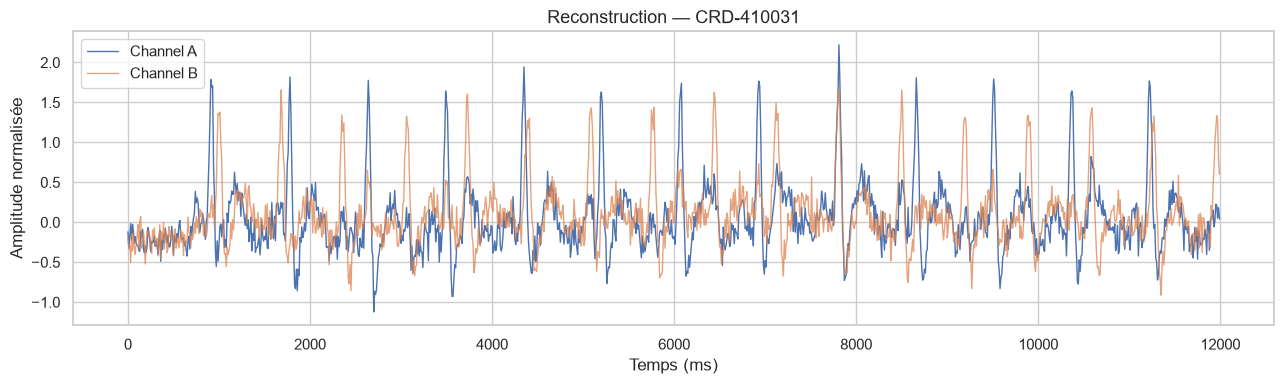

In [28]:
recording_id = cardiac_recordings.iloc[0]["recording_id"]
signal = cardiac_samples[cardiac_samples["recording_id"] == recording_id].sort_values("time_ms")

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(signal["time_ms"], signal["channel_a_normalized"], label="Channel A", linewidth=1)
ax.plot(signal["time_ms"], signal["channel_b_normalized"], label="Channel B", alpha=0.75, linewidth=1)
ax.set_title(f"Reconstruction — {recording_id}")
ax.set_xlabel("Temps (ms)")
ax.set_ylabel("Amplitude normalisée")
ax.legend()
plt.tight_layout()
plt.show()


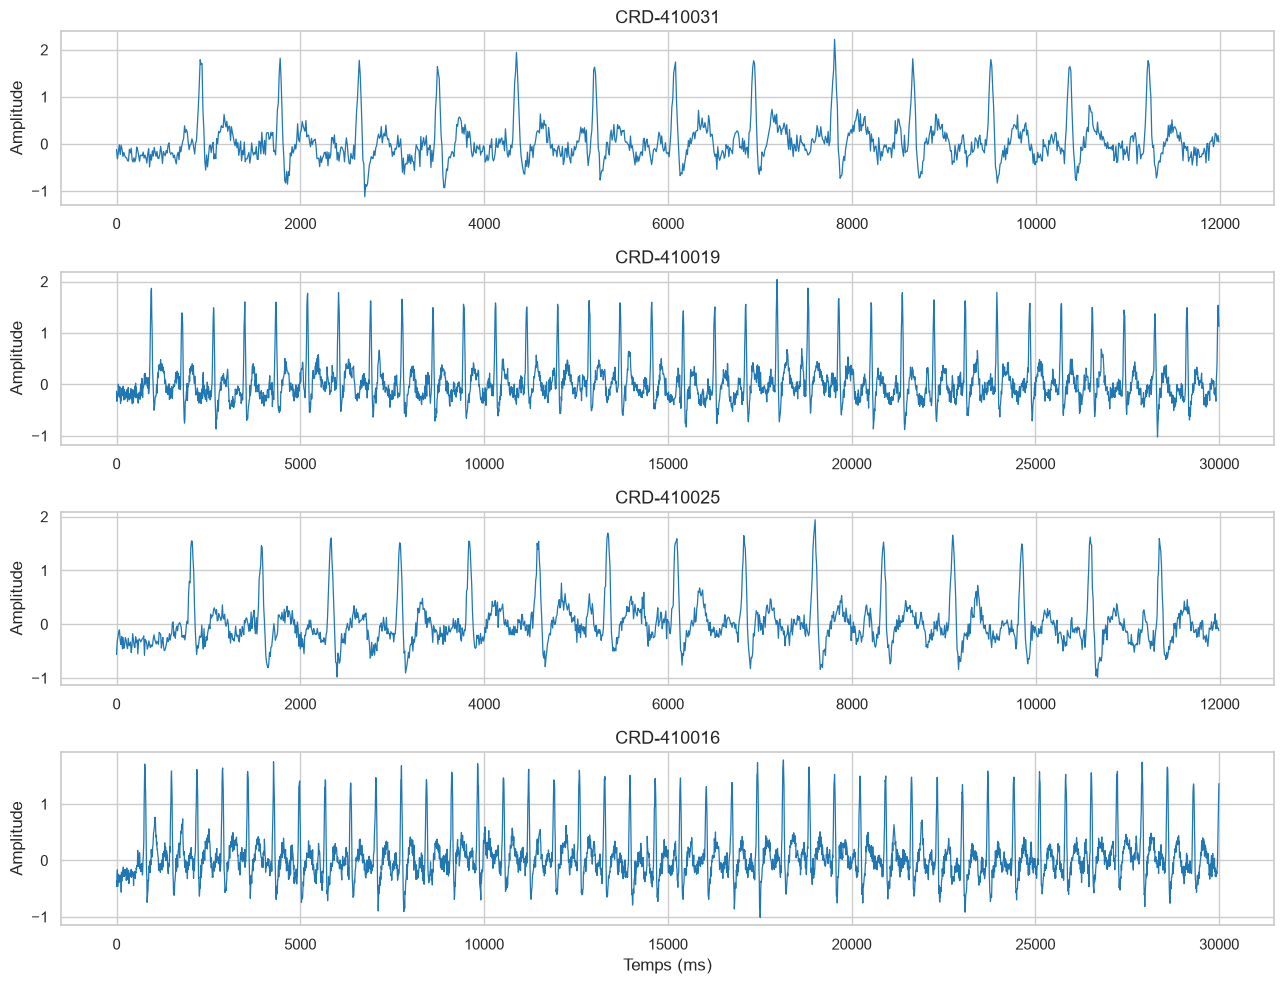

In [29]:
selected_ids = cardiac_recordings["recording_id"].head(4).tolist()
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=False)
for ax, rid in zip(axes, selected_ids):
    sig = cardiac_samples[cardiac_samples["recording_id"] == rid].sort_values("time_ms")
    ax.plot(sig["time_ms"], sig["channel_a_normalized"], color="tab:blue", linewidth=0.9)
    ax.set_title(rid)
    ax.set_ylabel("Amplitude")
axes[-1].set_xlabel("Temps (ms)")
plt.tight_layout()
plt.show()


### Interprétation (C.2)

Les courbes se reconstruisent correctement dans le temps (deux canaux). On voit bien la forme du signal et les différences d'amplitude / régularité d'un enregistrement à l'autre. C'est surtout un contrôle visuel avant les stats et le clustering.

## C.3 Caractéristiques statistiques + estimation exploratoire du rythme

On va calculer plusieurs indicateurs pour chaque enregistrement et chaque canal.

**Les indicateurs utilisés :**

| **Indicateur** | **Signification** |
|---|---|
| Moyenne | Amplitude moyenne du signal |
| Écart-type | Dispersion du signal autour de sa moyenne |
| Minimum | Amplitude minimale |
| Maximum | Amplitude maximale |
| RMS | Amplitude quadratique moyenne |
| Peak-to-peak | Différence entre l'amplitude maximale et minimale |
| Zero crossings | Nombre de changements de signe du signal |

In [30]:
def extract_signal_features(signal_df):
    features = {}
    for channel in ["channel_a_normalized", "channel_b_normalized"]:
        x = signal_df[channel].dropna().values.astype(float)
        features[f"{channel}_mean"] = np.mean(x)
        features[f"{channel}_std"] = np.std(x)
        features[f"{channel}_min"] = np.min(x)
        features[f"{channel}_max"] = np.max(x)
        features[f"{channel}_rms"] = np.sqrt(np.mean(x ** 2))
        features[f"{channel}_ptp"] = np.ptp(x)
        features[f"{channel}_zero_crossings"] = int(np.sum(np.diff(np.signbit(x)) != 0))
    return features


def estimate_signal_rate(signal_df, sampling_rate):
    """Estimation EXPLORATOIRE via détection de pics — non clinique."""
    results = {}
    for channel in ["channel_a_normalized", "channel_b_normalized"]:
        x = signal_df[channel].dropna().values.astype(float)
        distance = max(1, int(float(sampling_rate) * 0.30))
        peaks, _ = find_peaks(x, distance=distance, prominence=np.std(x) * 0.5)
        if len(peaks) > 1:
            intervals = np.diff(peaks) / float(sampling_rate)
            results[f"{channel}_estimated_rate"] = 60.0 / np.mean(intervals)
            results[f"{channel}_interval_variability"] = float(np.std(intervals))
            results[f"{channel}_n_peaks"] = int(len(peaks))
        else:
            results[f"{channel}_estimated_rate"] = np.nan
            results[f"{channel}_interval_variability"] = np.nan
            results[f"{channel}_n_peaks"] = int(len(peaks))
    return results


# Calculer les caractéristiques des 44 enregistrements :
features_list = []
rate_list = []
meta_by_id = cardiac_recordings.set_index("recording_id")

for recording_id, group in cardiac_samples.groupby("recording_id"):
    group = group.sort_values("time_ms")
    feats = extract_signal_features(group)
    feats["recording_id"] = recording_id
    features_list.append(feats)

    sr = meta_by_id.loc[recording_id, "sampling_rate_hz"]
    rates = estimate_signal_rate(group, sr)
    rates["recording_id"] = recording_id
    rate_list.append(rates)

features_df = pd.DataFrame(features_list)
rate_df = pd.DataFrame(rate_list)

cardiac_analysis = (
    cardiac_recordings
    .merge(features_df, on="recording_id", how="left")
    .merge(rate_df, on="recording_id", how="left")
)

display(
    cardiac_analysis[[
        "recording_id", "patient_number", "encounter_number",
        "automated_interpretation", "device_quality",
        "channel_a_normalized_std", "channel_a_normalized_estimated_rate",
        "channel_a_normalized_interval_variability",
    ]].head(10)
)


,recording_id,patient_number,encounter_number,automated_interpretation,device_quality,channel_a_normalized_std,channel_a_normalized_estimated_rate,channel_a_normalized_interval_variability
0,CRD-410031,PAT-31162,ENC-000004,complex,80.9,0.443290,107.238606,0.211056
1,CRD-410019,PAT-31162,ENC-000004,irregular,88.0,0.409662,104.278075,0.217587
2,CRD-410025,PAT-31040,ENC-000007,review_required,84.8,0.427381,125.838926,0.175213
3,CRD-410016,PAT-31115,ENC-000017,inconclusive,86.7,0.417615,123.626374,0.172540
4,CRD-410014,PAT-31233,ENC-000033,complex,93.0,0.421553,98.594742,0.212492
5,CRD-410038,PAT-31065,ENC-000038,irregular,86.0,0.409524,116.219008,0.230790
6,CRD-410005,PAT-31065,ENC-000038,review_required,85.5,0.418127,101.902174,0.233106
7,CRD-410022,PAT-31037,ENC-000053,inconclusive,94.2,0.421292,88.732394,0.211446
8,CRD-410001,PAT-31221,ENC-000061,normal,76.9,0.462836,119.250426,0.191427
9,CRD-410021,PAT-31119,ENC-000076,inconclusive,81.9,0.496720,138.956101,0.169538


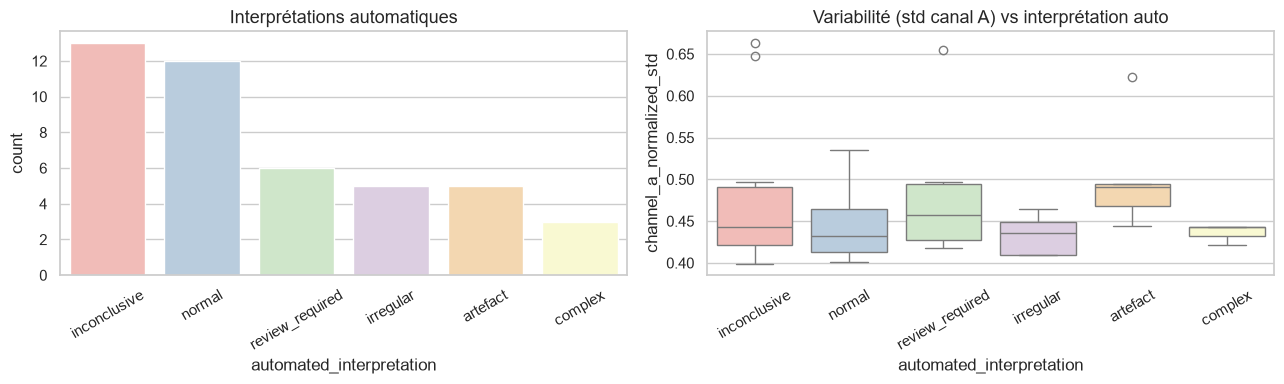

In [31]:
# Comparer les interprétations automatiques
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = cardiac_analysis["automated_interpretation"].value_counts().index
sns.countplot(data=cardiac_analysis, x="automated_interpretation", order=order, ax=axes[0], palette="Pastel1")
axes[0].set_title("Interprétations automatiques")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(
    data=cardiac_analysis, x="automated_interpretation",
    y="channel_a_normalized_std", order=order, ax=axes[1], palette="Pastel1",
)
axes[1].set_title("Variabilité (std canal A) vs interprétation auto")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


### Interprétation (C.3)

Pour chaque enregistrement on a des stats simples (écart-type, rythme estimé, variabilité des intervalles) + l'étiquette automatique (`normal`, `irregular`, `complex`, etc.). Les rythmes estimés tournent souvent autour de 90–140 selon le canal. C'est utile pour comparer les signaux entre eux, mais ce n'est pas un vrai diagnostic médical : juste une heuristique pour le projet.


## C.4 Clustering des signaux

On peut utiliser K-Means sur les caractéristiques numériques extraites.

Il faut standardiser les variables avant le clustering pour éviter que les échelles différentes influencent les résultats.

In [32]:
feature_columns = [c for c in features_df.columns if c != "recording_id"]
# Ajouter les indicateurs de rythme si disponibles
rate_feature_cols = [c for c in rate_df.columns if c != "recording_id"]
signal_features_full = features_df.merge(rate_df, on="recording_id", how="left")
feature_columns_full = [c for c in signal_features_full.columns if c != "recording_id"]
# standardiser
X_signals = signal_features_full[feature_columns_full].fillna(signal_features_full[feature_columns_full].median())
scaler = StandardScaler()
X_signals_scaled = scaler.fit_transform(X_signals)

# Choisir le nombre de clusters :
signal_scores = []
for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_signals_scaled)
    signal_scores.append({"k": k, "silhouette": silhouette_score(X_signals_scaled, labels)})

signal_scores_df = pd.DataFrame(signal_scores)
display(signal_scores_df)
# Appliquer le clustering :
best_signal_k = int(signal_scores_df.loc[signal_scores_df["silhouette"].idxmax(), "k"])
signal_model = KMeans(n_clusters=best_signal_k, random_state=42, n_init=20)
signal_features_full["signal_cluster"] = signal_model.fit_predict(X_signals_scaled)
print("K signaux retenu :", best_signal_k)
# Comparer les clusters avec les interprétations automatiques :
comparison = cardiac_analysis.merge(
    signal_features_full[["recording_id", "signal_cluster"]],
    on="recording_id", how="left",
)
cardiac_analysis = comparison
display(pd.crosstab(comparison["signal_cluster"], comparison["automated_interpretation"]))


,k,silhouette
0,2,0.327929
1,3,0.195413
2,4,0.261568
3,5,0.253504
4,6,0.256628
5,7,0.268207


K signaux retenu : 2


automated_interpretation,artefact,complex,inconclusive,irregular,normal,review_required
signal_cluster,,,,,,
0,2,0,4,0,1,1
1,3,3,9,5,11,5


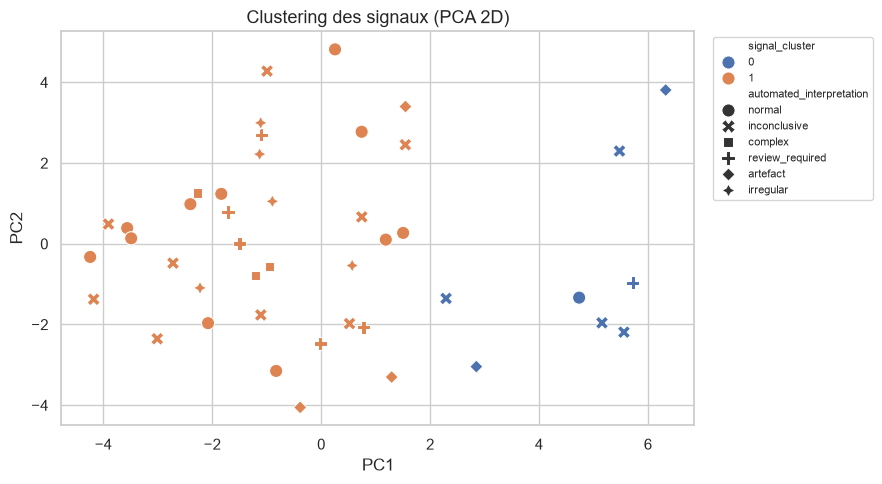

In [33]:
pca_s = PCA(n_components=2, random_state=42)
coords = pca_s.fit_transform(X_signals_scaled)
plot_df = signal_features_full.copy()
plot_df["PC1"] = coords[:, 0]
plot_df["PC2"] = coords[:, 1]
plot_df = plot_df.merge(
    cardiac_analysis[["recording_id", "automated_interpretation"]],
    on="recording_id", how="left",
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(
    data=plot_df, x="PC1", y="PC2",
    hue="signal_cluster", style="automated_interpretation", s=90, ax=ax,
)
ax.set_title("Clustering des signaux (PCA 2D)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


### Interprétation (C.4)

Pour les signaux, le meilleur silhouette est à **K = 2** (≈ 0.33). Le groupe 0 est petit et plus « atypique » (peu de `normal`), le groupe 1 concentre la majorité des recordings, y compris beaucoup de `normal` mais aussi d'autres labels. La PCA 2D sert juste à visualiser la séparation ; on ne force pas une lecture médicale dessus.

## C.5 Liaison signaux ↔ patients ↔ notes cliniques

Clés : `recording_id`, `patient_number`, `encounter_number`.

Cette étape est essentielle pour ton projet, car elle permet de croiser les résultats numériques avec les observations textuelles.


In [34]:
# Relier les enregistrements aux notes cliniques
cardiac_notes = cardiac_recordings.merge(
    clinical_notes,
    on=["patient_number", "encounter_number"],
    how="left",
    suffixes=("_recording", "_note"),
)
# Rechercher les termes liés au rythme cardiaque
cardiac_keywords = [
    "arrhythmia", "irregular rhythm", "rhythm variability", "palpitations",
    "tachycardia", "bradycardia", "ectopic", "pulse", "heartbeat",
    "contraction", "cardiac", "rhythm", "ecg", "heart rate",
]

# Rechercher les termes liés au rythme cardiaque
def find_cardiac_terms(text):
    if pd.isna(text):
        return []
    text_l = str(text).lower()
    return [kw for kw in cardiac_keywords if kw in text_l]


cardiac_notes["detected_terms"] = cardiac_notes["text"].apply(find_cardiac_terms)
cardiac_notes["has_cardiac_terms"] = cardiac_notes["detected_terms"].apply(len) > 0

display(
    cardiac_notes[[
        "recording_id", "patient_number", "encounter_number",
        "automated_interpretation", "document_id", "title", "detected_terms",
    ]].head(15)
)

print("\nCouverture notes liées :", cardiac_notes["document_id"].notna().mean() * 100, "%")
display(pd.crosstab(cardiac_notes["automated_interpretation"], cardiac_notes["has_cardiac_terms"]))


,recording_id,patient_number,encounter_number,automated_interpretation,document_id,title,detected_terms
0,CRD-410031,PAT-31162,ENC-000004,complex,NaN,NaN,[]
1,CRD-410019,PAT-31162,ENC-000004,irregular,NaN,NaN,[]
2,CRD-410025,PAT-31040,ENC-000007,review_required,NaN,NaN,[]
3,CRD-410016,PAT-31115,ENC-000017,inconclusive,NaN,NaN,[]
4,CRD-410014,PAT-31233,ENC-000033,complex,NaN,NaN,[]
5,CRD-410038,PAT-31065,ENC-000038,irregular,CLN-510025,Restricted Phenotype and Public-Identity Resolution,[rhythm]
6,CRD-410005,PAT-31065,ENC-000038,review_required,CLN-510025,Restricted Phenotype and Public-Identity Resolution,[rhythm]
7,CRD-410022,PAT-31037,ENC-000053,inconclusive,CLN-510010,Clinical Summary 04,[pulse]
8,CRD-410001,PAT-31221,ENC-000061,normal,NaN,NaN,[]
9,CRD-410021,PAT-31119,ENC-000076,inconclusive,NaN,NaN,[]



Couverture notes liées : 9.090909090909092 %


has_cardiac_terms,False,True
automated_interpretation,,
artefact,5,0
complex,3,0
inconclusive,12,1
irregular,4,1
normal,11,1
review_required,5,1


In [35]:
# Enrichir avec clusters / rythme puis sauvegarder
cardiac_notes = cardiac_notes.merge(
    cardiac_analysis[[
        "recording_id", "signal_cluster",
        "channel_a_normalized_estimated_rate",
        "channel_a_normalized_interval_variability",
        "channel_a_normalized_std",
    ]],
    on="recording_id",
    how="left",
)

cardiac_analysis.to_csv(f"{OUTPUT_PATH}/cardiac_features.csv", index=False)
cardiac_notes.to_csv(f"{OUTPUT_PATH}/cardiac_clinical_links.csv", index=False)
print("Sauvegardés : cardiac_features.csv | cardiac_clinical_links.csv")


Sauvegardés : cardiac_features.csv | cardiac_clinical_links.csv


### Interprétation (C.5)

Peu de recordings ont une note clinique directement liée (~9 %). Parmi les cas utiles : PAT-31065 (signaux `irregular` / `review_required`) est relié à la note CLN-510025 qui parle de `rhythm` ; PAT-31037 a une note qui mentionne `pulse`. Ce sont des pistes pour le narratif (signal + texte), pas des preuves médicales. Limite : si la note n'utilise pas le mot-clé, on peut rater le lien.


---
# Partie D — Synthèse, livrables et limites

> **Mission 10** — Rédiger la section de rapport : méthode, résultats, limites.  
> **Mission 11** — Relire la section du développeur 1 (hors de ce notebook) : méthode claire, résultats reproductibles.


In [36]:
print("=" * 60)
print("RESUME QUANTITATIF DE LA PARTIE 6")
print("=" * 60)
print(f"Documents analysés           : {len(documents)}")
print(f"Clusters textuels (K)        : {documents['cluster'].nunique()}")
print(f"Références extraites         : {len(references_df)}")
if len(references_df):
    print(f"Références validées (True)   : {int(references_df['exists_in_csv'].fillna(False).sum())}")
print(f"Entités structurées          : {len(entities_extracted)}")
print(f"Enregistrements cardiaques   : {len(cardiac_recordings)}")
print(f"Clusters signaux (K)         : {cardiac_analysis['signal_cluster'].nunique()}")
print(f"Liens recording↔note non nuls: {cardiac_notes['document_id'].notna().sum()}")
print("\nFichiers dans outputs/ :")
for f in sorted(os.listdir(OUTPUT_PATH)):
    print(" -", f)


RESUME QUANTITATIF DE LA PARTIE 6
Documents analysés           : 130
Clusters textuels (K)        : 7
Références extraites         : 143
Références validées (True)   : 138
Entités structurées          : 268
Enregistrements cardiaques   : 44
Clusters signaux (K)         : 2
Liens recording↔note non nuls: 4

Fichiers dans outputs/ :
 - atypical_documents.csv
 - cardiac_clinical_links.csv
 - cardiac_features.csv
 - cardiac_qc.csv
 - entity_centrality.csv
 - extracted_entities.csv
 - prepared_documents.csv


## Conclusions

### 1. Ce que cette partie apporte au secret caché
Le but du projet n'est pas juste de faire tourner des algos : c'est de **retrouver un narratif caché** dans des données factices. Ici, on a des indices dans trois directions qui se croisent :

- des **thèmes textuels** (7 clusters) ;
- des **liens vérifiés** entre textes et CSV (shipments, patients, sites…) ;
- des **signaux cardiaques** parfois irréguliers, reliés à des notes cliniques.

Méthodes du cours réellement utilisées : regroupement (K-Means), détection d'anomalies / patterns, fouille de graphes (cooccurrences), séries temporelles (signaux), fouille de textes (TF-IDF, n-grammes).

### 2. Pistes concrètes (vérifiables)

1. **Chaîne logistique** : des `SHP-...` / `PO-...` dans les mémos existent bien dans `logistics/` (ex. SHP-2022-00011 ↔ MEM-510100). Taux de validation des références : **96,5 %** (138/143).
2. **Trous utiles** : les 5 IDs non trouvés sont surtout des `ACC-...` (dossiers réglementaires). Ça peut être une piste du secret (référence volontairement hors table), ou juste un autre format / système.
3. **Acteurs centraux** : Valenne Central District, Threshold Earth Observatory, Lantern Investigative Bureau, Horizon Field Research Cooperative reviennent souvent dans le graphe — bons points pour relier public / écologie / enquête.
4. **Santé + identité** : PAT-31065 a des signaux `irregular` / `review_required` (CRD-410038, CRD-410005) et une note CLN-510025 qui parle de `rhythm`. Rare cas où texte + signal se renforcent.
5. **Documents hors norme** : lettres / archives (PUB-510043, PUB-510046…) sont atypiques et collent aux clusters « identité / continuité / provenance » — utile pour une piste historique du narratif.

### 3. Limites
Données synthétiques → pas de conclusion hors projet. NLP lexical, clustering sensible à K, rythme cardiaque seulement exploratoire, croisements dépendants des regex / clés.

### 4. Reproductibilité
`random_state=42`, contrôles de cardinalité, exports dans `outputs/`. Environnement : `requirements.txt` + lancement depuis la racine du dépôt (cf. `README.md`).
